In [ ]:
from pathlib import Path
from collections import defaultdict

import meshio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.collections as mc
from scipy.spatial import cKDTree

BASE = Path('results_SENT_FULLY_CORRECTED')

mesh = meshio.read(BASE / 'mesh.msh')
coords = mesh.points[:, :2]
tris   = mesh.cells_dict['triangle']

# ── merge duplicate nodes ─────────────────────────────────────────────────
tree  = cKDTree(coords)
pairs = tree.query_pairs(r=1e-10)
parent = list(range(len(coords)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

for a, b in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

remap      = np.array([find(i) for i in range(len(coords))])
unique_ids, inv = np.unique(remap, return_inverse=True)
merged_coords   = coords[unique_ids]
merged_tris     = inv[tris].astype(int)

# ── boundary loops ────────────────────────────────────────────────────────
edge_count = {}
for tri in merged_tris:
    for i in range(3):
        a, b = tri[i], tri[(i+1)%3]
        key  = (min(a,b), max(a,b))
        edge_count[key] = edge_count.get(key, 0) + 1

bdy_edges = {e for e, cnt in edge_count.items() if cnt == 1}
adj = defaultdict(list)
for a, b in bdy_edges:
    adj[a].append(b); adj[b].append(a)

visited, loops = set(), []
for start in adj:
    if start in visited: continue
    chain = [start]; visited.add(start); cur = start
    while True:
        nxt = [n for n in adj[cur] if n not in visited]
        if not nxt: break
        nxt = nxt[0]; visited.add(nxt); chain.append(nxt); cur = nxt
    if len(chain) > 1:
        loops.append(np.array([merged_coords[n] for n in chain]))

def poly_area(pts):
    x, y = pts[:,0], pts[:,1]
    return 0.5 * abs(np.dot(x, np.roll(y,-1)) - np.dot(y, np.roll(x,-1)))

outer_idx = int(np.argmax([poly_area(lp) for lp in loops]))

# ── plot ──────────────────────────────────────────────────────────────────
xmin, ymin = coords.min(axis=0)
xmax, ymax = coords.max(axis=0)
padx = 0.04*(xmax-xmin)
pady = 0.04*(ymax-ymin)

fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=200)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.add_collection(mc.PolyCollection(
    coords[tris], facecolor='#B8D4E8', edgecolor='none', zorder=1))
ax.triplot(coords[:,0], coords[:,1], tris,
           color='#5A8FAA', linewidth=0.25, zorder=2)

for i, loop in enumerate(loops):
    closed = np.vstack([loop, loop[0]])
    lw = 2.5 if i == outer_idx else 1.2
    ax.plot(closed[:,0], closed[:,1],
            color='black', linewidth=lw,
            solid_capstyle='round', solid_joinstyle='round', zorder=3)

ax.set_xlim(xmin - padx, xmax + padx)
ax.set_ylim(ymin - pady, ymax + pady)
ax.set_aspect('equal')
ax.axis('off')
plt.tight_layout(pad=0.2)
plt.show()

Loading …
Done.


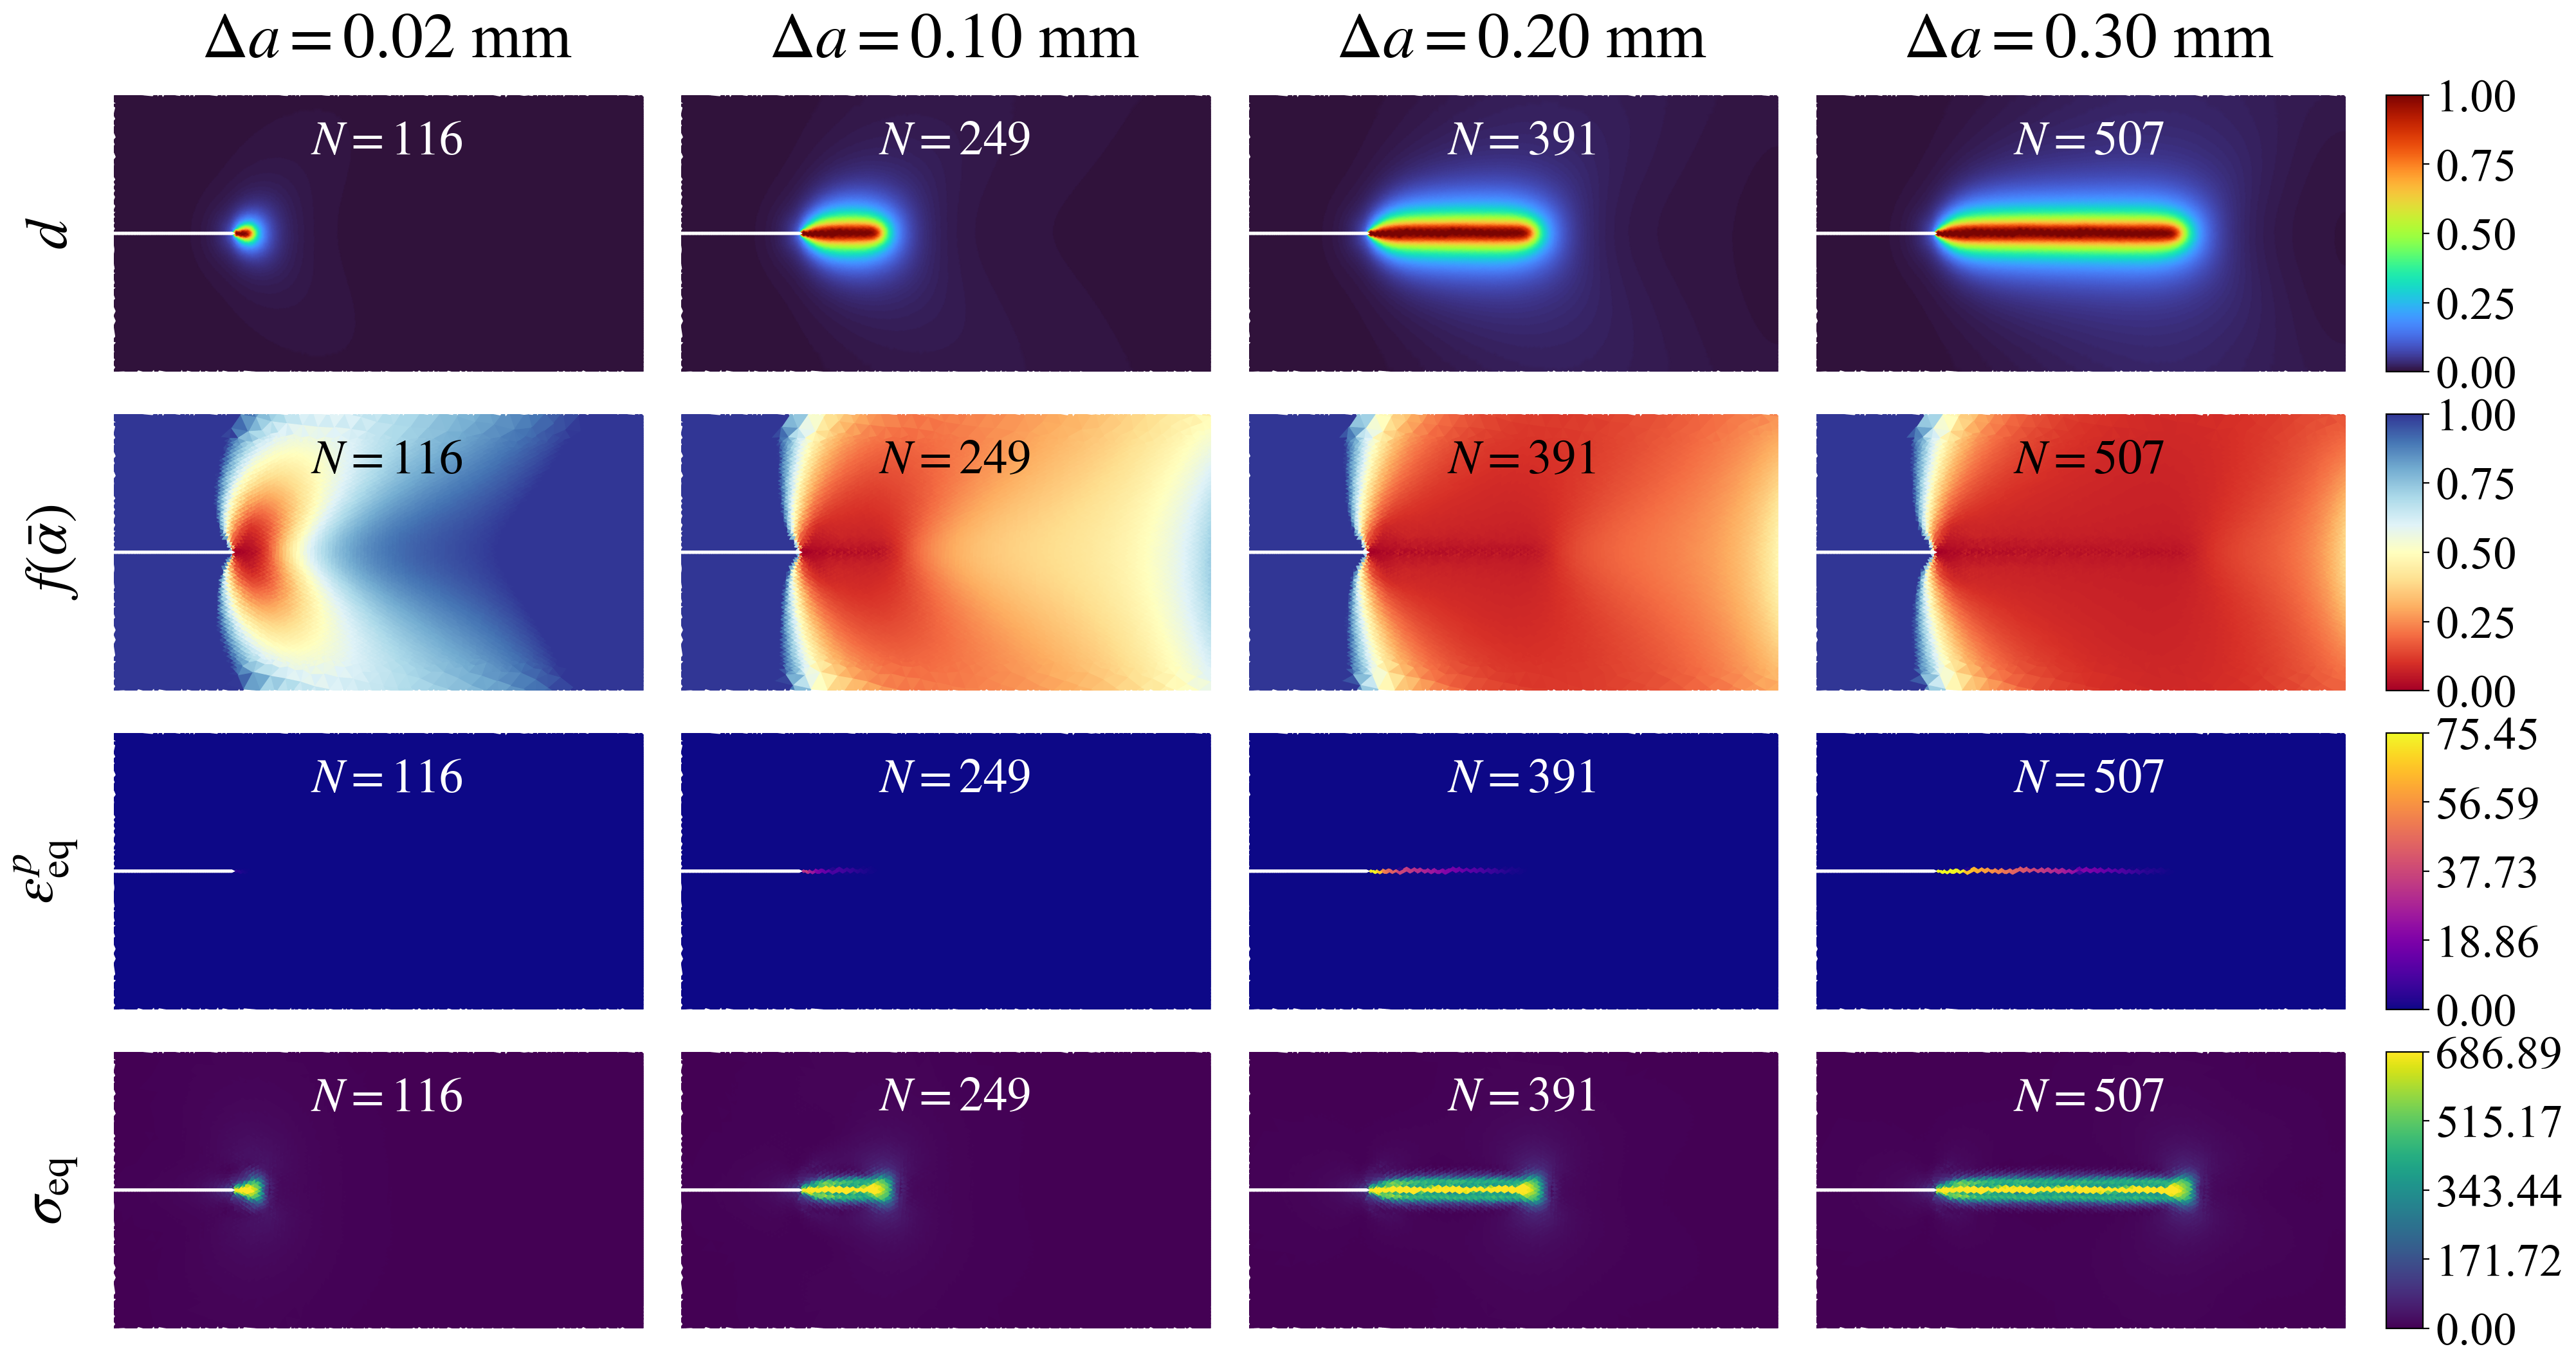

In [6]:
from pathlib import Path
import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.gridspec import GridSpec
import meshio

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        32,
    'figure.dpi':       200,
})

BASE      = Path('results_SENT_FULLY_CORRECTED')
BORDER_LW = 2.0

# Crop to crack-tip region: x slightly behind pre-crack tip, full width to right
CROP_X = (0.35, 1.02)
CROP_Y = (0.33, 0.67)

# 4 milestone snapshots: (filename, Δa label, N)
SNAPSHOTS = [
    ('result_a20_N000116.vtu',  0.02, 116),
    ('result_a100_N000249.vtu', 0.10, 249),
    ('result_a200_N000391.vtu', 0.20, 391),
    ('result_a300_N000507.vtu', 0.30, 507),
]
N_COLS = len(SNAPSHOTS)
N_ROWS = 4

alpha_T = 11.25
def fatigue_degradation(ab):
    return np.where(ab <= alpha_T, 1.0, (2*alpha_T / (ab + alpha_T))**2)

# regular N-step files (nearest to milestone N) that contain sigmaeq
REGULAR_FILES = [
    'result_N000120.vtu',   # ≈ N=116
    'result_N000250.vtu',   # ≈ N=249
    'result_N000390.vtu',   # ≈ N=391
    'result_N000510.vtu',   # ≈ N=507
]

# ── load snapshots ────────────────────────────────────────────────────────
print('Loading …')
snaps = []
for (fname, da, N), rfname in zip(SNAPSHOTS, REGULAR_FILES):
    mesh  = meshio.read(BASE / fname)
    rmesh = meshio.read(BASE / rfname)
    pts   = mesh.points[:, :2]
    cells = next(cb.data for cb in mesh.cells
                 if cb.type in ('triangle', 'triangle6'))
    if cells.shape[1] > 3:
        cells = cells[:, :3]
    cx = pts[cells, 0].mean(axis=1)
    cy = pts[cells, 1].mean(axis=1)
    mask = ((cx >= CROP_X[0]) & (cx <= CROP_X[1]) &
            (cy >= CROP_Y[0]) & (cy <= CROP_Y[1]))
    tri = mtri.Triangulation(pts[:, 0], pts[:, 1], triangles=cells[mask])
    ab  = mesh.point_data['alpha_bar'].ravel()
    sq  = rmesh.point_data['sigmaeq'].ravel()
    snaps.append({
        'tri': tri,
        'd':   mesh.point_data['d'].ravel(),
        'fa':  fatigue_degradation(ab),
        'ep':  mesh.point_data['epspeq'].ravel(),
        'sq':  sq,
        'da':  da,
        'N':   N,
    })
print('Done.')

# ── color limits ──────────────────────────────────────────────────────────
all_ep  = snaps[-1]['ep']
nz_ep   = all_ep[all_ep > 1e-4]
EP_MAX  = float(np.percentile(nz_ep, 99)) if len(nz_ep) > 0 else float(all_ep.max())

all_sq  = snaps[-1]['sq']
nz_sq   = all_sq[all_sq > 1e-4]
SQ_MAX  = float(np.percentile(nz_sq, 99)) if len(nz_sq) > 0 else float(all_sq.max())

# rows: field key, colormap, norm, left-label
ROWS = [
    ('d',  'turbo',   mpl.colors.Normalize(0.0, 1.0),    '$d$'),
    ('fa', 'RdYlBu',  mpl.colors.Normalize(0.0, 1.0),    r'$f(\bar{\alpha})$'),
    ('ep', 'plasma',  mpl.colors.Normalize(0.0, EP_MAX),  r'$\varepsilon^p_{\mathrm{eq}}$'),
    ('sq', 'viridis',  mpl.colors.Normalize(0.0, SQ_MAX),  r'$\sigma_{\mathrm{eq}}$'),
]

# ── figure ────────────────────────────────────────────────────────────────
crop_w = CROP_X[1] - CROP_X[0]
crop_h = CROP_Y[1] - CROP_Y[0]
CELL_W = 4.2
CELL_H = CELL_W * crop_h / crop_w

L_PAD, R_PAD = 0.55, 1.0
T_PAD, B_PAD = 0.65, 0.25
HS, WS = 0.13, 0.04

fig_w = L_PAD + N_COLS * CELL_W * (1 + WS) + R_PAD
fig_h = T_PAD + N_ROWS * CELL_H * (1 + HS) + B_PAD
fig   = plt.figure(figsize=(fig_w, fig_h))

lf = L_PAD / fig_w;  rf = 1 - R_PAD / fig_w
bf = B_PAD / fig_h;  tf = 1 - T_PAD / fig_h
gs = GridSpec(N_ROWS, N_COLS, figure=fig,
              left=lf, right=rf, bottom=bf, top=tf,
              hspace=HS, wspace=WS)
ax_grid = [[fig.add_subplot(gs[r, c])
            for c in range(N_COLS)] for r in range(N_ROWS)]

for r, (fkey, cmap_name, norm, _) in enumerate(ROWS):
    for c, snap in enumerate(snaps):
        ax  = ax_grid[r][c]
        ax.tripcolor(snap['tri'], snap[fkey],
                     cmap=cmap_name, norm=norm,
                     shading='gouraud', rasterized=True)
        ax.set_xlim(CROP_X)
        ax.set_ylim(CROP_Y)
        ax.set_aspect('equal')
        ax.axis('off')
        for sp in ax.spines.values():
            sp.set_visible(True)
            sp.set_linewidth(BORDER_LW)
            sp.set_edgecolor('black')

        # N = xxx inside panel, top
        txt_color = 'black' if r == 1 else 'white'
        ax.text(0.50, 0.91,
                rf'$N = {snap["N"]}$',
                transform=ax.transAxes,
                ha='center', va='top',
                fontsize=27, color=txt_color, zorder=10)

# ── column headers ────────────────────────────────────────────────────────
fig.canvas.draw()
for c, snap in enumerate(snaps):
    pos = ax_grid[0][c].get_position()
    fig.text(0.5 * (pos.x0 + pos.x1),
             pos.y1 + 0.018,
             rf'$\Delta a = {snap["da"]:.2f}$ mm',
             ha='center', va='bottom',
             fontsize=36)

# ── row labels (left) ─────────────────────────────────────────────────────
for r, (_, _, _, label) in enumerate(ROWS):
    pos = ax_grid[r][0].get_position()
    fig.text(lf - 0.014, 0.5 * (pos.y0 + pos.y1),
             label,
             ha='right', va='center', fontsize=33, rotation=90)

# ── colorbars (right, ticks only – no title) ──────────────────────────────
for r, (_, cmap_name, norm, _) in enumerate(ROWS):
    pos = ax_grid[r][N_COLS-1].get_position()
    cax = fig.add_axes([pos.x1 + 0.010, pos.y0,
                        0.015, pos.y1 - pos.y0])
    cb  = fig.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=cmap_name), cax=cax)
    cb.set_ticks(np.linspace(norm.vmin, norm.vmax, 5))
    cb.ax.yaxis.set_major_formatter(
        mpl.ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
    cb.ax.tick_params(labelsize=26)

plt.show()

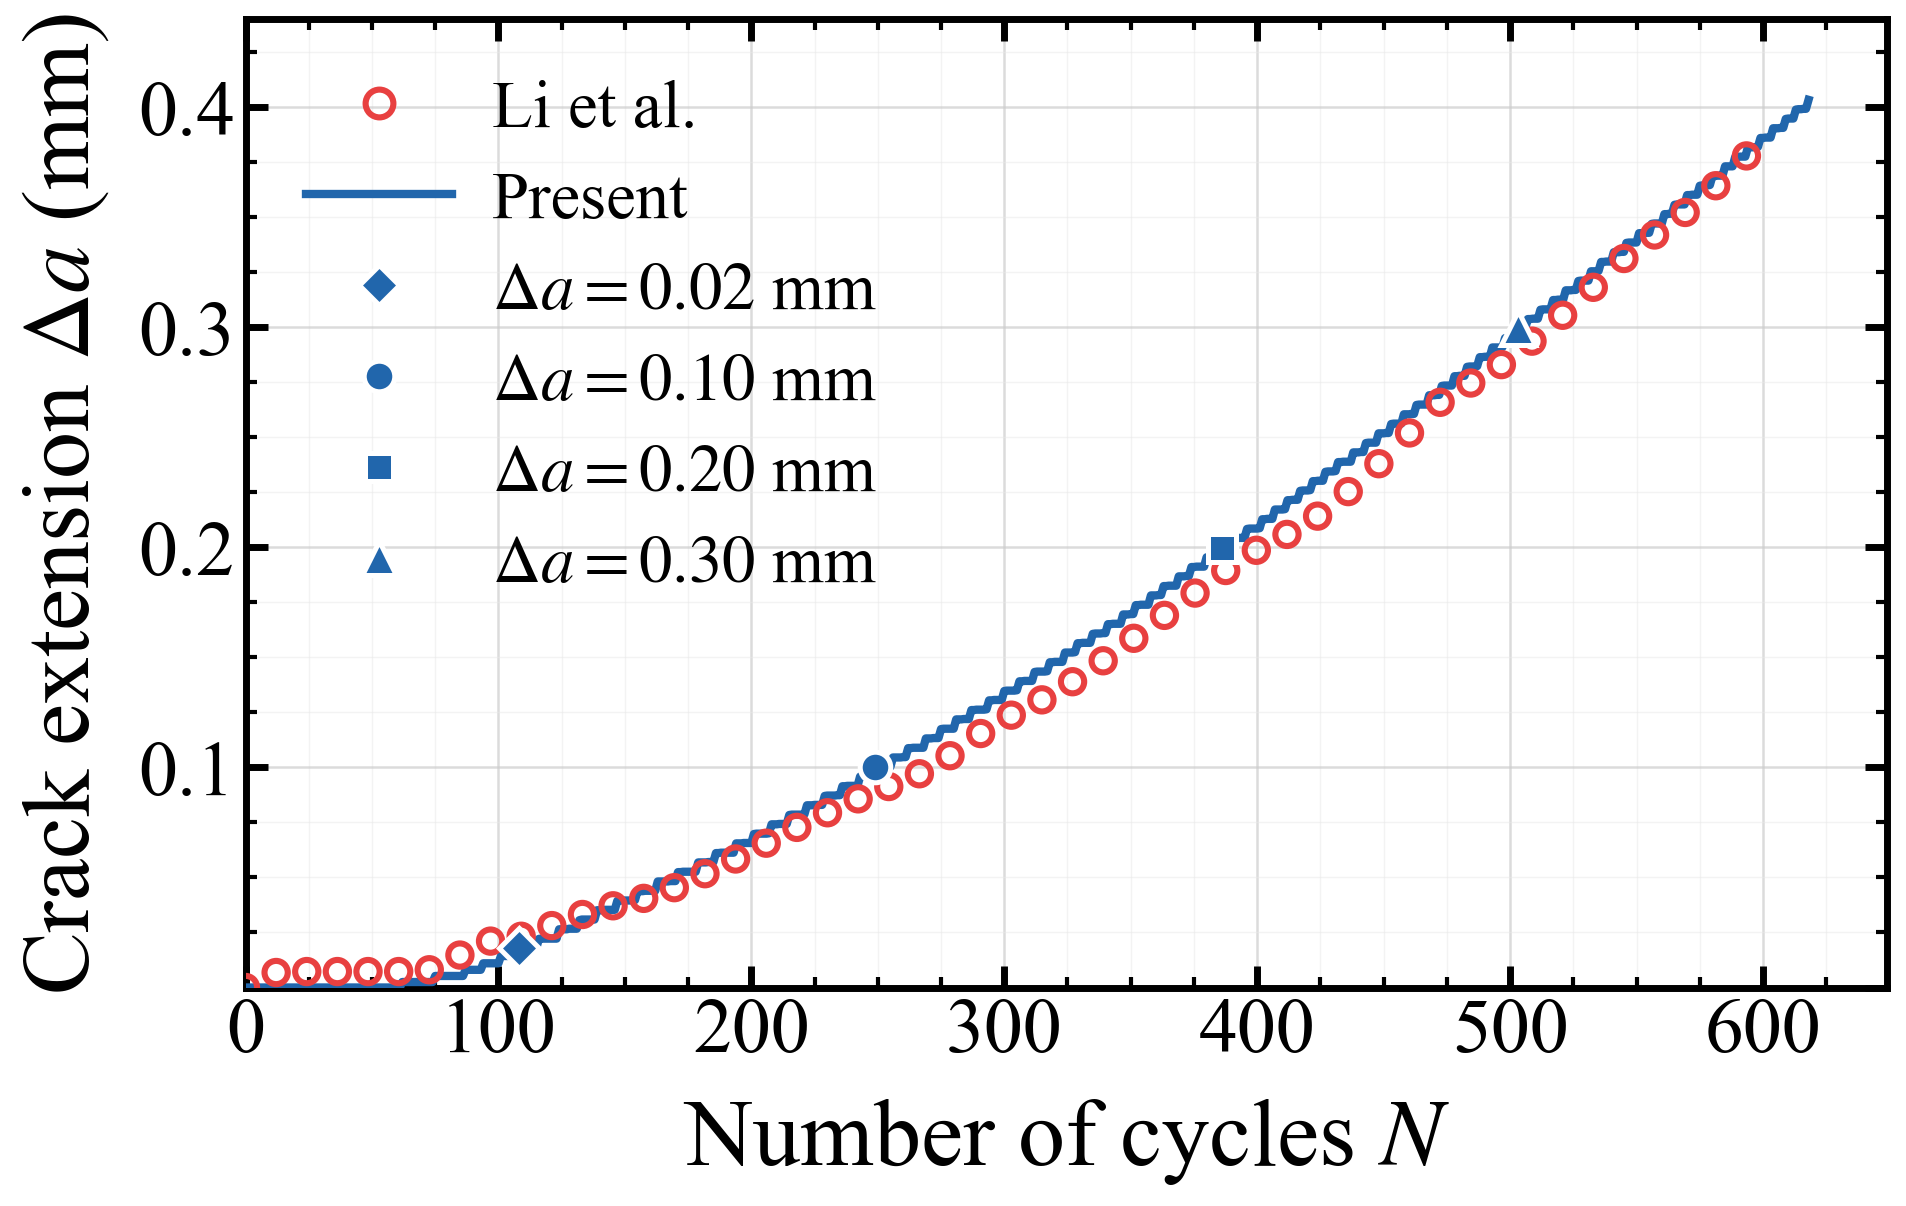

In [14]:
from pathlib import Path
import csv
import numpy as np
from scipy.interpolate import PchipInterpolator
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        30,
    'figure.dpi':       200,
})

BASE = Path('results_SENT_FULLY_CORRECTED')

# ── load simulation ───────────────────────────────────────────────────────
sim_N, sim_da = [], []
with open(BASE / 'cycle_summary.csv') as f:
    for row in csv.DictReader(f):
        sim_N.append(int(row['N']))
        sim_da.append(float(row['delta_a_mm']))
sim_N  = np.array(sim_N)
sim_da = np.array(sim_da)

# ── load & smooth reference (clip Δa ≤ 0.40) ─────────────────────────────
ref_N_raw, ref_da_raw = [], []
with open(BASE / 'SENTjia.csv', encoding='utf-8-sig') as f:
    for row in csv.reader(f):
        if row:
            da = float(row[1]) - 0.5
            if da <= 0.40:
                ref_N_raw.append(float(row[0]))
                ref_da_raw.append(da)
ref_N_raw  = np.array(ref_N_raw)
ref_da_raw = np.array(ref_da_raw)

# force origin + deduplicate + PCHIP fit
N_fit  = np.concatenate([[0.0], ref_N_raw])
da_fit = np.concatenate([[0.0], ref_da_raw])
_, idx_u = np.unique(N_fit, return_index=True)
pchip = PchipInterpolator(N_fit[idx_u], da_fit[idx_u])

# re-sample at uniform N grid for even point density across whole range
ref_N  = np.linspace(0, ref_N_raw[-1], 50)
ref_da = np.clip(pchip(ref_N), 0, None)

# ── snapshot milestones ───────────────────────────────────────────────────
DA_MILESTONES = [0.02, 0.10, 0.20, 0.30]
MS_MARKERS    = ['D',  'o',  's',  '^']
MS_SIZES      = [10,   11,   10,   12]

# ── figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6.5))

ax.set_axisbelow(True)
ax.grid(True, which='major', color='#CCCCCC', linewidth=0.9, alpha=0.7)
ax.grid(True, which='minor', color='#E8E8E8', linewidth=0.5, alpha=0.5)

# reference: smoothed values displayed as hollow circles
ax.scatter(ref_N, ref_da,
           s=70, marker='o',
           facecolor='none', edgecolor='#E84040',
           linewidth=2.2, zorder=5)

# simulation line
ax.plot(sim_N, sim_da,
        color='#2166AC', linewidth=3.0,
        linestyle='-', zorder=4)

# milestone markers on simulation curve
for da_t, mk, ms in zip(DA_MILESTONES, MS_MARKERS, MS_SIZES):
    idx2 = np.argmin(np.abs(sim_da - da_t))
    ax.plot(sim_N[idx2], sim_da[idx2],
            marker=mk, markersize=ms,
            color='#2166AC',
            markeredgecolor='white', markeredgewidth=1.8,
            linestyle='none', zorder=7)

# ── axes styling ──────────────────────────────────────────────────────────
ax.set_xlabel(r'Number of cycles $N$',            fontsize=34, labelpad=10)
ax.set_ylabel(r'Crack extension $\Delta a$ (mm)', fontsize=34, labelpad=10)

ax.tick_params(axis='both', which='major',
               labelsize=28, width=2.5, length=8, direction='in',
               top=True, right=True)
ax.tick_params(axis='both', which='minor',
               width=1.5, length=4, direction='in',
               top=True, right=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(100))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(25))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.025))
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: '' if x == 0 else f'{x:.1f}'))

for spine in ax.spines.values():
    spine.set_linewidth(2.5)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0, top=0.44)
ax.margins(x=0.03)

# ── legend ────────────────────────────────────────────────────────────────
main_handles = [
    Line2D([0],[0], marker='o', markersize=10,
           markerfacecolor='none', markeredgecolor='#E84040',
           markeredgewidth=2.2, linestyle='none',
           label='Li et al. '),
    Line2D([0],[0], color='#2166AC', linewidth=3.0, linestyle='-',
           label='Present'),
]
ms_handles = [
    Line2D([0],[0], marker=mk, markersize=ms,
           color='#2166AC',
           markeredgecolor='white', markeredgewidth=1.8,
           linestyle='none',
           label=rf'$\Delta a = {da:.2f}$ mm')
    for da, mk, ms in zip(DA_MILESTONES, MS_MARKERS, MS_SIZES)
]

ax.legend(handles=main_handles + ms_handles,
          fontsize=24, frameon=False,
          loc='upper left',
          handlelength=2.2, handletextpad=0.6,
          borderaxespad=0.5, labelspacing=0.45)

plt.tight_layout(pad=0.8)
plt.show()

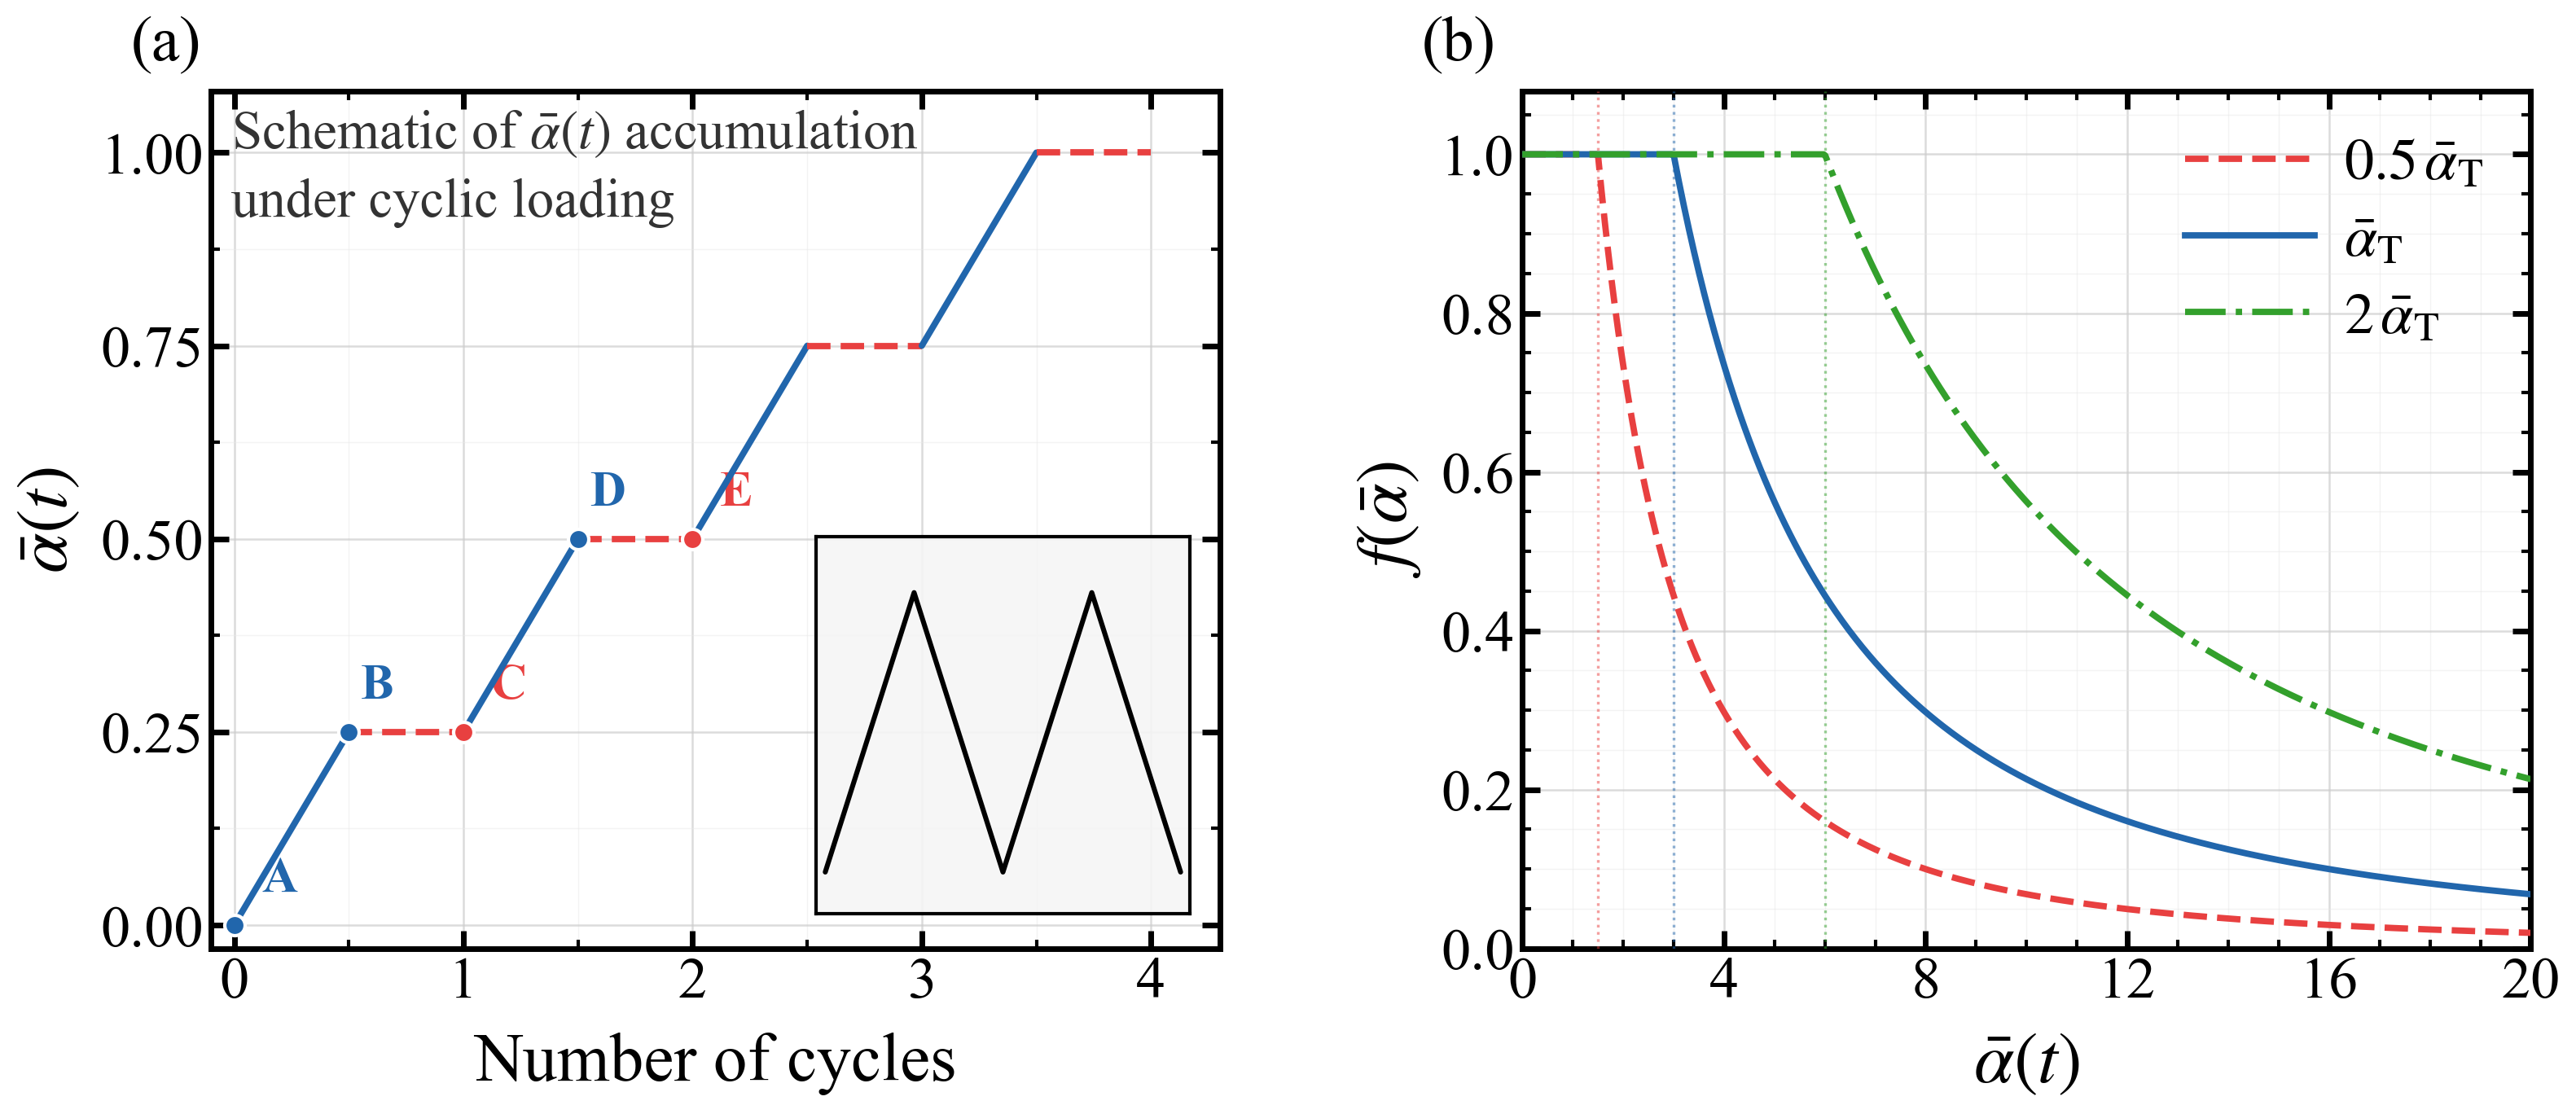

In [13]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        28,
    'figure.dpi':       200,
})

BLUE  = '#2166AC'
RED   = '#E84040'
GREEN = '#33A02C'

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))
plt.subplots_adjust(left=0.08, right=0.97, bottom=0.14, top=0.95, wspace=0.30)

segs = [
    (0,   0.5, 0,    0.25, BLUE, '-' ),
    (0.5, 1.0, 0.25, 0.25, RED,  '--'),
    (1.0, 1.5, 0.25, 0.5,  BLUE, '-' ),
    (1.5, 2.0, 0.5,  0.5,  RED,  '--'),
    (2.0, 2.5, 0.5,  0.75, BLUE, '-' ),
    (2.5, 3.0, 0.75, 0.75, RED,  '--'),
    (3.0, 3.5, 0.75, 1.0,  BLUE, '-' ),
    (3.5, 4.0, 1.0,  1.0,  RED,  '--'),
]
for x0,x1,y0,y1,col,ls in segs:
    ax1.plot([x0,x1],[y0,y1], color=col, lw=2.8, ls=ls,
             solid_capstyle='round', zorder=4)

pts = [('A', (0,   0   ), BLUE, ( 0.12, 0.03)),
       ('B', (0.5, 0.25), BLUE, ( 0.05, 0.03)),
       ('C', (1.0, 0.25), RED,  ( 0.12, 0.03)),
       ('D', (1.5, 0.5 ), BLUE, ( 0.05, 0.03)),
       ('E', (2.0, 0.5 ), RED,  ( 0.12, 0.03))]
for name,(x,y),col,(ox,oy) in pts:
    ax1.plot(x, y, 'o', color=col, ms=9, zorder=6,
             markeredgecolor='white', markeredgewidth=1.5)
    ax1.text(x+ox, y+oy, name, fontsize=22, color=col,
             va='bottom', fontweight='bold')

ax1.set_xlabel('Number of cycles', fontsize=30, labelpad=10)
ax1.set_ylabel(r'$\bar{\alpha}(t)$', fontsize=32, labelpad=8)
ax1.set_xlim(-0.10, 4.30)
ax1.set_ylim(-0.03, 1.08)
ax1.xaxis.set_major_locator(ticker.MultipleLocator(1.0))
ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.xaxis.set_minor_locator(ticker.MultipleLocator(0.5))
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(0.125))
ax1.tick_params(axis='both', which='major', labelsize=26, width=2.5,
                length=8, direction='in', top=True, right=True)
ax1.tick_params(axis='both', which='minor', width=1.5,
                length=4, direction='in', top=True, right=True)
ax1.grid(True, which='major', color='#CCCCCC', lw=0.9, alpha=0.7)
ax1.grid(True, which='minor', color='#E8E8E8', lw=0.5, alpha=0.5)
ax1.set_axisbelow(True)
for sp in ax1.spines.values():
    sp.set_linewidth(2.5)

ax1.text(-0.08, 1.02, '(a)', transform=ax1.transAxes,
         fontsize=28, ha='left', va='bottom')
ax1.text(0.02, 0.98, r'Schematic of $\bar{\alpha}(t)$ accumulation' + '\n' + r'under cyclic loading',
         transform=ax1.transAxes, fontsize=24, ha='left', va='top',
         color='#333333', linespacing=1.5)

axins = ax1.inset_axes([0.60, 0.04, 0.37, 0.44])
t_w = np.array([0, 0.5, 1.0, 1.5, 2.0])
u_w = np.array([0, 1.0, 0,   1.0, 0  ])
axins.plot(t_w, u_w, 'k-', lw=2.2, solid_capstyle='round', zorder=4)
axins.set_xlim(-0.05, 2.05)
axins.set_ylim(-0.15, 1.20)
axins.set_xticks([])
axins.set_yticks([])
for sp in axins.spines.values():
    sp.set_linewidth(1.5)
axins.patch.set_facecolor('#F5F5F5')
axins.patch.set_alpha(0.90)

alpha_T_ref = 3.0
AT_CASES = [
    (0.5*alpha_T_ref, r'$0.5\,\bar{\alpha}_\mathrm{T}$', RED,   '--'),
    (    alpha_T_ref, r'$\bar{\alpha}_\mathrm{T}$',        BLUE,  '-' ),
    (2.0*alpha_T_ref, r'$2\,\bar{\alpha}_\mathrm{T}$',    GREEN, '-.'),
]

alpha = np.linspace(0, 20, 600)
handles = []
for aT, lbl, col, ls in AT_CASES:
    f_val = np.where(alpha <= aT, 1.0, (2*aT / (alpha + aT))**2)
    ax2.plot(alpha, f_val, color=col, lw=2.8, ls=ls, zorder=4)
    ax2.axvline(aT, color=col, ls=':', lw=1.2, alpha=0.5, zorder=3)
    handles.append(Line2D([0],[0], color=col, lw=2.8, ls=ls, label=lbl))

ax2.set_xlabel(r'$\bar{\alpha}(t)$',  fontsize=32, labelpad=10)
ax2.set_ylabel(r'$f(\bar{\alpha})$', fontsize=32, labelpad=8)
ax2.set_xlim(0, 20)
ax2.set_ylim(0, 1.08)
ax2.xaxis.set_major_locator(ticker.MultipleLocator(4))
ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.2))
ax2.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax2.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
ax2.tick_params(axis='both', which='major', labelsize=26, width=2.5,
                length=8, direction='in', top=True, right=True)
ax2.tick_params(axis='both', which='minor', width=1.5,
                length=4, direction='in', top=True, right=True)
ax2.grid(True, which='major', color='#CCCCCC', lw=0.9, alpha=0.7)
ax2.grid(True, which='minor', color='#E8E8E8', lw=0.5, alpha=0.5)
ax2.set_axisbelow(True)
for sp in ax2.spines.values():
    sp.set_linewidth(2.5)
ax2.legend(handles=handles, fontsize=26, frameon=False,
           loc='upper right', handlelength=2.2,
           handletextpad=0.5, labelspacing=0.4, borderaxespad=0.4)
ax2.text(-0.10, 1.02, '(b)', transform=ax2.transAxes,
         fontsize=28, ha='left', va='bottom')

plt.show()